<a href="https://colab.research.google.com/github/petkuteliepa-del/DI-darbas/blob/main/lt_tree_full_workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lithuanian tree identifier: full workflow (one notebook)

Run the cells **top to bottom, one at a time**. Part A builds the image dataset, Part B trains the model.

| Step | What it does | Time |
|---|---|---|
| 0 | Check GPU | seconds |
| 1 | Set up Drive + libraries | 1-2 min |
| 2 | Write the download script | seconds |
| 3 | `count`: how many images exist per species | 1-2 min |
| 4 | Small test download (2 species) | few min |
| 5 | Full download | 30-90 min |
| 6 | `label`: guess leaf/bark/whole tree/fruit | 10-30 min |
| 7 | `review`: look at the labels | seconds |
| 8+ | Train, evaluate, save the model | 10-30 min |

**Do this first:** Runtime > Change runtime type > **T4 GPU** > Save. Do it *before* running anything, because changing it later restarts the session and erases the script file.

If Colab disconnects, reconnect and rerun steps 0, 1 and 2 again (not the downloads). Then continue. Downloads resume where they stopped.

## Step 0: check the GPU

In [1]:
import torch
print('GPU available:', torch.cuda.is_available())
if not torch.cuda.is_available():
    print('No GPU. Runtime > Change runtime type > T4 GPU, then rerun from the top.')

GPU available: True


## Step 1: Google Drive, libraries and folder settings

In [2]:
!pip -q install open_clip_torch scikit-learn pandas matplotlib seaborn pillow tqdm joblib requests

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
DATA_ROOT = Path('/content/drive/MyDrive/lt_trees')
MANIFEST  = DATA_ROOT / 'manifest.csv'
OUT_DIR   = DATA_ROOT / 'model_out'
OUT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
print('Data folder:', DATA_ROOT)

Mounted at /content/drive
Data folder: /content/drive/MyDrive/lt_trees


# Part A: build the image dataset

## Step 2: write the download script
This cell saves the script as `gbif_download.py` in the Colab session. Run it once per session.

In [3]:
%%writefile gbif_download.py
#!/usr/bin/env python3
"""
Download training images for the Lithuanian tree identifier from GBIF
(iNaturalist research-grade observations), log licence + observer, and write
the manifest.csv expected by lt_tree_classifier_training.ipynb.

Stages (run in this order):
  count     how many licence-allowed images exist per species (quick, no download)
  download  download images and write/extend manifest.csv
  label     guess the organ (leaf/bark/whole_tree/fruit) for each image (zero-shot CLIP)
  review    make contact sheets so you can eyeball the organ labels

Example (Colab):
  !python gbif_download.py count    --out /content/drive/MyDrive/lt_trees
  !python gbif_download.py download --out /content/drive/MyDrive/lt_trees --target 800
  !python gbif_download.py label    --out /content/drive/MyDrive/lt_trees
  !python gbif_download.py review   --out /content/drive/MyDrive/lt_trees
"""
import argparse, io, random, re, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

GBIF_API = "https://api.gbif.org/v1"
INAT_DATASET = "50c9509d-22c7-4a22-a47d-8c48425ef4a7"   # iNaturalist Research-grade Observations

SPECIES = [
    "Picea abies", "Pinus sylvestris", "Juniperus communis", "Taxus baccata", "Larix decidua",
    "Alnus glutinosa", "Alnus incana", "Betula pendula", "Betula pubescens",
    "Populus tremula", "Populus nigra", "Quercus robur", "Quercus petraea",
    "Carpinus betulus", "Tilia cordata", "Acer platanoides", "Fraxinus excelsior",
    "Fagus sylvatica", "Ulmus glabra", "Ulmus laevis", "Ulmus minor",
    "Salix alba", "Salix fragilis", "Salix caprea", "Sorbus aucuparia",
    "Malus sylvestris", "Pyrus pyraster", "Prunus padus",
]

# Search order: nearest first, then wider. Stops as soon as enough images are found.
GEOGRAPHIES = [
    {"country": "LT"}, {"country": "LV"}, {"country": "EE"}, {"country": "PL"},
    {"country": "FI"}, {"country": "SE"}, {"country": "DK"}, {"country": "DE"},
    {"continent": "EUROPE"},
]

# GBIF filter enum  ->  short name used in the manifest
LICENSES = {"CC0_1_0": "CC0", "CC_BY_4_0": "CC-BY", "CC_BY_NC_4_0": "CC-BY-NC"}

ORGANS = ["leaf", "bark", "whole_tree", "fruit"]
ORGAN_PROMPTS = {
    "leaf": ["a close-up photo of tree leaves", "a photo of a branch with leaves",
             "a photo of a single leaf", "a photo of conifer needles on a twig"],
    "bark": ["a close-up photo of tree bark", "the bark of a tree trunk",
             "a photo of rough bark texture"],
    "whole_tree": ["a photo of a whole tree", "a tree standing in a landscape",
                   "trees in a forest", "a photo of a tree crown"],
    "fruit": ["a photo of fruits on a tree", "a photo of tree seeds",
              "a photo of cones on a conifer", "a photo of acorns or nuts",
              "a photo of berries on a branch", "a photo of winged seeds"],
    "other": ["a photo of a flower", "a photo of tree catkins", "a photo of a person",
              "a photo of an insect or animal", "a photo of a mushroom or lichen",
              "a photo of a building or a road", "a screenshot or text"],
}


def slug(name): return name.lower().replace(" ", "_")


def norm_license(value):
    """Map a GBIF licence URL/string to CC0 / CC-BY / CC-BY-NC (or the raw value)."""
    v = (value or "").lower()
    if "publicdomain/zero" in v or v in ("cc0", "cc0_1_0"): return "CC0"
    if "licenses/by-nc" in v or "cc_by_nc" in v: return "CC-BY-NC"
    if "licenses/by/" in v or v in ("cc_by_4_0", "cc-by"): return "CC-BY"
    return value or ""


def rewrite_url(url, size):
    """iNaturalist open-data photos exist as small/medium/large/original; use a smaller one."""
    if "inaturalist" in url and size != "original":
        return re.sub(r"/(original|large|medium|small)\.(\w+)(\?.*)?$", rf"/{size}.\2", url)
    return url


def get_json(session, url, params, tries=4):
    for k in range(tries):
        try:
            r = session.get(url, params=params, timeout=60)
            r.raise_for_status()
            return r.json()
        except Exception:
            if k == tries - 1: raise
            time.sleep(2 ** k)


def match_taxon(session, name):
    d = get_json(session, f"{GBIF_API}/species/match", {"name": name, "rank": "species"})
    key = d.get("speciesKey") or d.get("usageKey")
    if not key or d.get("matchType") == "NONE":
        raise RuntimeError(f"GBIF could not match {name!r}")
    return key, d.get("scientificName", "?"), d.get("status", "?")


def search_params(key, geo, licenses, offset, limit):
    p = [("taxonKey", key), ("mediaType", "StillImage"), ("datasetKey", INAT_DATASET),
         ("occurrenceStatus", "PRESENT"), ("limit", limit), ("offset", offset)]
    p += [("license", l) for l in licenses]
    p += list(geo.items())
    return p


def count_images(session, key, geo, licenses):
    d = get_json(session, f"{GBIF_API}/occurrence/search", search_params(key, geo, licenses, 0, 0))
    return d["count"]


def fetch_candidates(session, key, licenses, want, max_per_obs, max_per_occ):
    allowed = {LICENSES[l] for l in licenses}
    seen, per_obs, cands = set(), Counter(), []
    for geo in GEOGRAPHIES:
        offset = 0
        while len(cands) < want and offset <= 99700:
            d = get_json(session, f"{GBIF_API}/occurrence/search",
                         search_params(key, geo, licenses, offset, 300))
            for occ in d.get("results", []):
                if occ["key"] in seen: continue
                seen.add(occ["key"])
                media = [m for m in occ.get("media", [])
                         if m.get("type") == "StillImage" and m.get("identifier")]
                for i, m in enumerate(media[:max_per_occ]):
                    lic = norm_license(m.get("license") or occ.get("license"))
                    if lic not in allowed: continue
                    obs = (occ.get("recordedBy") or m.get("creator")
                           or occ.get("rightsHolder") or "unknown").strip()
                    if per_obs[obs] >= max_per_obs: continue
                    per_obs[obs] += 1
                    cands.append({"gbif_id": occ["key"], "idx": i, "url": m["identifier"],
                                  "observer": obs, "license": lic,
                                  "country": occ.get("countryCode", ""),
                                  "date": (occ.get("eventDate") or "")[:10],
                                  "source": m.get("references") or occ.get("references") or ""})
            if d.get("endOfRecords"): break
            offset += 300
        if len(cands) >= want: break
    return cands[:want]


def download_one(c, species, out_dir, size, max_side):
    from PIL import Image
    import requests
    rel = Path("images") / slug(species) / f"{c['gbif_id']}_{c['idx']}.jpg"
    dest = out_dir / rel
    row = {"file": rel.as_posix(), "species": species, "organ": "unlabeled",
           "observer": c["observer"], "license": c["license"], "source_url": c["url"],
           "occurrence_page": c["source"], "gbif_id": c["gbif_id"],
           "country": c["country"], "date": c["date"]}
    if dest.exists(): return row
    dest.parent.mkdir(parents=True, exist_ok=True)
    url = rewrite_url(c["url"], size)
    for k in range(3):
        try:
            r = requests.get(url, timeout=60); r.raise_for_status()
            im = Image.open(io.BytesIO(r.content)).convert("RGB")
            im.thumbnail((max_side, max_side))
            im.save(dest, "JPEG", quality=90)
            return row
        except Exception:
            time.sleep(2 ** k)
    return None


# ----------------------------------------------------------------- stages
def stage_count(a):
    import requests
    s = requests.Session()
    lic = list(LICENSES) if a.include_nc else ["CC0_1_0", "CC_BY_4_0"]
    print(f"{'species':<22}{'matched as':<34}{'LT':>6}{'Baltic+':>9}{'Europe':>9}")
    for sp in SPECIES:
        key, matched, status = match_taxon(s, sp)
        lt = count_images(s, key, {"country": "LT"}, lic)
        bal = lt + sum(count_images(s, key, {"country": c}, lic) for c in ("LV", "EE"))
        eu = count_images(s, key, {"continent": "EUROPE"}, lic)
        flag = "" if status == "ACCEPTED" else f"  [{status}]"
        print(f"{sp:<22}{matched[:32]:<34}{lt:>6}{bal:>9}{eu:>9}{flag}")
    print("\nCounts are occurrences with photos; most have 1-4 photos each.")


def stage_download(a):
    import pandas as pd, requests
    from tqdm.auto import tqdm
    out = Path(a.out); out.mkdir(parents=True, exist_ok=True)
    s = requests.Session()
    lic = list(LICENSES) if a.include_nc else ["CC0_1_0", "CC_BY_4_0"]
    man_path = out / "manifest.csv"
    old = pd.read_csv(man_path) if man_path.exists() else pd.DataFrame()
    species = [x for x in SPECIES if not a.only or x in a.only]
    new_rows = []
    for sp in species:
        have = int((old.species == sp).sum()) if len(old) else 0
        need = a.target - have
        if need <= 0:
            print(f"{sp}: already {have} images, skipping"); continue
        key, matched, status = match_taxon(s, sp)
        print(f"\n{sp}  (GBIF: {matched}, {status})  need {need}")
        cands = fetch_candidates(s, key, lic, int(need * 1.3), a.max_per_observer, a.max_per_obs_record)
        if len(old):   # skip what we already have
            have_files = set(old.file)
            cands = [c for c in cands if f"images/{slug(sp)}/{c['gbif_id']}_{c['idx']}.jpg" not in have_files]
        ok = 0
        with ThreadPoolExecutor(a.workers) as ex:
            futs = [ex.submit(download_one, c, sp, out, a.size, a.max_side) for c in cands]
            for f in tqdm(as_completed(futs), total=len(futs), desc=sp):
                r = f.result()
                if r: new_rows.append(r); ok += 1
        print(f"  downloaded {ok} / {len(cands)} candidates")
        # save after every species so a Colab disconnect loses little
        pd.concat([old, pd.DataFrame(new_rows)], ignore_index=True).drop_duplicates("file").to_csv(man_path, index=False)
    man = pd.read_csv(man_path)
    man[["file", "species", "observer", "license", "source_url", "occurrence_page"]].to_csv(out / "ATTRIBUTION.csv", index=False)
    print(f"\nManifest: {man_path}  ({len(man)} images)")
    print("Images per species:\n", man.species.value_counts().to_string())
    print("\nNext: run the 'label' stage to fill in the organ column.")


def stage_label(a):
    import pandas as pd, torch, open_clip
    from PIL import Image
    from tqdm.auto import tqdm
    out = Path(a.out); man_path = out / "manifest.csv"
    df = pd.read_csv(man_path)
    if "organ_conf" not in df: df["organ_conf"] = float("nan")
    todo = df.index[df.organ_conf.isna()].tolist()
    print(len(todo), "images to label")
    if not todo: return
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    model, _, pre = open_clip.create_model_and_transforms("ViT-B-32", pretrained="openai")
    tok = open_clip.get_tokenizer("ViT-B-32")
    model = model.to(dev).eval()
    names = ORGANS + ["other"]
    with torch.no_grad():
        T = []
        for n in names:
            t = model.encode_text(tok(ORGAN_PROMPTS[n]).to(dev))
            t = torch.nn.functional.normalize(t.float(), dim=-1).mean(0)
            T.append(torch.nn.functional.normalize(t, dim=0))
        T = torch.stack(T)
    for i in tqdm(range(0, len(todo), a.batch)):
        idx = todo[i:i + a.batch]
        ims, keep = [], []
        for j in idx:
            try:
                ims.append(pre(Image.open(out / df.at[j, "file"]).convert("RGB"))); keep.append(j)
            except Exception:
                df.at[j, "organ"] = "unlabeled"; df.at[j, "organ_conf"] = 0.0
        if not ims: continue
        with torch.no_grad():
            f = torch.nn.functional.normalize(model.encode_image(torch.stack(ims).to(dev)).float(), dim=-1)
            p = (100.0 * f @ T.T).softmax(-1).cpu()
        for j, row in zip(keep, p):
            k = int(row.argmax()); conf = float(row[k])
            df.at[j, "organ_conf"] = conf
            df.at[j, "organ"] = names[k] if (names[k] != "other" and conf >= a.min_conf) else "unlabeled"
        if (i // a.batch) % 20 == 0: df.to_csv(man_path, index=False)
    df.to_csv(man_path, index=False)
    print(df.pivot_table(index="species", columns="organ", values="file", aggfunc="count", fill_value=0))
    print("\n'unlabeled' rows are ignored by the training notebook. Run 'review' to check the labels.")


def stage_review(a):
    import pandas as pd
    from PIL import Image
    out = Path(a.out); df = pd.read_csv(out / "manifest.csv")
    (out / "review").mkdir(exist_ok=True)
    rnd = random.Random(0); th, cols = 160, 8
    for organ in ORGANS + ["unlabeled"]:
        sub = df[df.organ == organ]
        if sub.empty: continue
        pick = sub.sample(min(a.n, len(sub)), random_state=0)
        rows = (len(pick) + cols - 1) // cols
        sheet = Image.new("RGB", (cols * th, rows * th), "white")
        for k, f in enumerate(pick.file):
            try:
                im = Image.open(out / f).convert("RGB"); im.thumbnail((th, th))
                sheet.paste(im, ((k % cols) * th, (k // cols) * th))
            except Exception: pass
        sheet.save(out / "review" / f"{organ}.jpg", quality=85)
        print(f"wrote review/{organ}.jpg  ({len(pick)} random images labelled '{organ}')")


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("stage", choices=["count", "download", "label", "review"])
    ap.add_argument("--out", required=True, help="dataset folder (e.g. on Google Drive)")
    ap.add_argument("--target", type=int, default=800, help="images wanted per species")
    ap.add_argument("--only", nargs="*", help="restrict to these Latin names")
    ap.add_argument("--include-nc", action="store_true", help="also allow CC-BY-NC images")
    ap.add_argument("--max-per-observer", type=int, default=25, help="cap per observer per species")
    ap.add_argument("--max-per-obs-record", type=int, default=3, help="max photos from one observation")
    ap.add_argument("--size", default="medium", choices=["small", "medium", "large", "original"])
    ap.add_argument("--max-side", type=int, default=768)
    ap.add_argument("--workers", type=int, default=8)
    ap.add_argument("--batch", type=int, default=64)
    ap.add_argument("--min-conf", type=float, default=0.5, help="organ label confidence cut-off")
    ap.add_argument("--n", type=int, default=48, help="images per review sheet")
    a = ap.parse_args()
    {"count": stage_count, "download": stage_download, "label": stage_label, "review": stage_review}[a.stage](a)


if __name__ == "__main__":
    main()


Writing gbif_download.py


## Step 3: count the available images
Shows how many licence-allowed photos exist per species (Lithuania / Baltic / all Europe). Nothing is downloaded. Check the "matched as" column for wrong names. Species with under about 300 in Europe will be weak.

In [4]:
!python gbif_download.py count --out {DATA_ROOT}

species               matched as                            LT  Baltic+   Europe
Picea abies           Picea abies (L.) H.Karst.            151      664     5832
Pinus sylvestris      Pinus sylvestris L.                  184      642     9977
Juniperus communis    Juniperus communis L.                 53      113     5078
Taxus baccata         Taxus baccata L.                       2        4     5115
Larix decidua         Larix decidua Mill.                    0        1     1633
Alnus glutinosa       Alnus glutinosa (L.) Gaertn.          32       68     7871
Alnus incana          Alnus incana (L.) Moench              16       26     1568
Betula pendula        Betula pendula Roth                   15       27     5345
Betula pubescens      Betula pubescens Ehrh.                 6        9     1537
Populus tremula       Populus tremula L.                    50       64     4652
Populus nigra         Populus nigra L.                       0        1     1124
Quercus robur         Quercu

## Step 4: small test download
Downloads 50 images each for two species, to check that everything works. Afterwards, look in Drive: `lt_trees/images/` should contain JPEGs and `manifest.csv` should exist.

In [5]:
!python gbif_download.py download --out {DATA_ROOT} --target 50 --only "Picea abies" "Betula pendula"


Picea abies  (GBIF: Picea abies (L.) H.Karst., ACCEPTED)  need 50
Picea abies: 100% 65/65 [00:11<00:00,  5.65it/s]
  downloaded 65 / 65 candidates

Betula pendula  (GBIF: Betula pendula Roth, ACCEPTED)  need 50
Betula pendula: 100% 65/65 [00:10<00:00,  6.23it/s]
  downloaded 65 / 65 candidates

Manifest: /content/drive/MyDrive/lt_trees/manifest.csv  (130 images)
Images per species:
 species
Picea abies       65
Betula pendula    65

Next: run the 'label' stage to fill in the organ column.


## Step 5: full download
Downloads up to 800 images per species. Takes roughly 30-90 minutes: keep the tab open. If it stops, rerun this cell and it continues.

In [6]:
..!python gbif_download.py download --out {DATA_ROOT} --target 800


Picea abies  (GBIF: Picea abies (L.) H.Karst., ACCEPTED)  need 735
Picea abies: 100% 890/890 [02:26<00:00,  6.08it/s]
  downloaded 890 / 890 candidates

Pinus sylvestris  (GBIF: Pinus sylvestris L., ACCEPTED)  need 800
Pinus sylvestris: 100% 1040/1040 [02:50<00:00,  6.08it/s]
  downloaded 1040 / 1040 candidates

Juniperus communis  (GBIF: Juniperus communis L., ACCEPTED)  need 800
Juniperus communis: 100% 1040/1040 [02:55<00:00,  5.92it/s]
  downloaded 1040 / 1040 candidates

Taxus baccata  (GBIF: Taxus baccata L., ACCEPTED)  need 800
Taxus baccata: 100% 1040/1040 [02:51<00:00,  6.08it/s]
  downloaded 1040 / 1040 candidates

Larix decidua  (GBIF: Larix decidua Mill., ACCEPTED)  need 800
Larix decidua: 100% 1040/1040 [02:47<00:00,  6.19it/s]
  downloaded 1040 / 1040 candidates

Alnus glutinosa  (GBIF: Alnus glutinosa (L.) Gaertn., ACCEPTED)  need 800
Alnus glutinosa: 100% 1040/1040 [02:48<00:00,  6.17it/s]
  downloaded 1040 / 1040 candidates

Alnus incana  (GBIF: Alnus incana (L.) Moen

## Step 6: label the organs
Guesses whether each photo shows a leaf, bark, the whole tree or fruit/seed. Photos it is unsure about (and flowers, people, insects) are marked `unlabeled` and are ignored in training.

In [7]:
!python gbif_download.py label --out {DATA_ROOT}

21670 images to label

open_clip_model.safetensors: downloading bytes:  56% 340M/605M [00:02<00:01, 159MB/s, 29.3MB/s  ]
open_clip_model.safetensors: downloading bytes:  60% 365M/605M [00:03<00:01, 132MB/s, 30.9MB/s  ]
open_clip_model.safetensors: downloading bytes:  70% 425M/605M [00:03<00:01, 103MB/s, 34.6MB/s  ]
open_clip_model.safetensors: reconstructing file:  78% 470M/605M [00:03<00:00, 138MB/s, 30.6MB/s  ]
open_clip_model.safetensors: downloading bytes: 100% 432M/432M [00:04<00:00, 88.9MB/s, 35.2MB/s  ]
open_clip_model.safetensors: reconstructing file: 100% 605M/605M [00:04<00:00, 125MB/s, 50.3MB/s  ]
/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(
100% 339/339 [04:14<00:00,  1.33it/s]
organ               bark  fruit  leaf  unlabeled  whole_tree
species                                                     
Acer platanoides

## Step 7: review the labels
Creates sheets of random images per organ. **Check them.** `leaf` should mostly show leaves, `bark` mostly bark, and so on. If a sheet is clearly wrong, tell me before training.

wrote review/leaf.jpg  (48 random images labelled 'leaf')
wrote review/bark.jpg  (48 random images labelled 'bark')
wrote review/whole_tree.jpg  (48 random images labelled 'whole_tree')
wrote review/fruit.jpg  (48 random images labelled 'fruit')
wrote review/unlabeled.jpg  (48 random images labelled 'unlabeled')
leaf


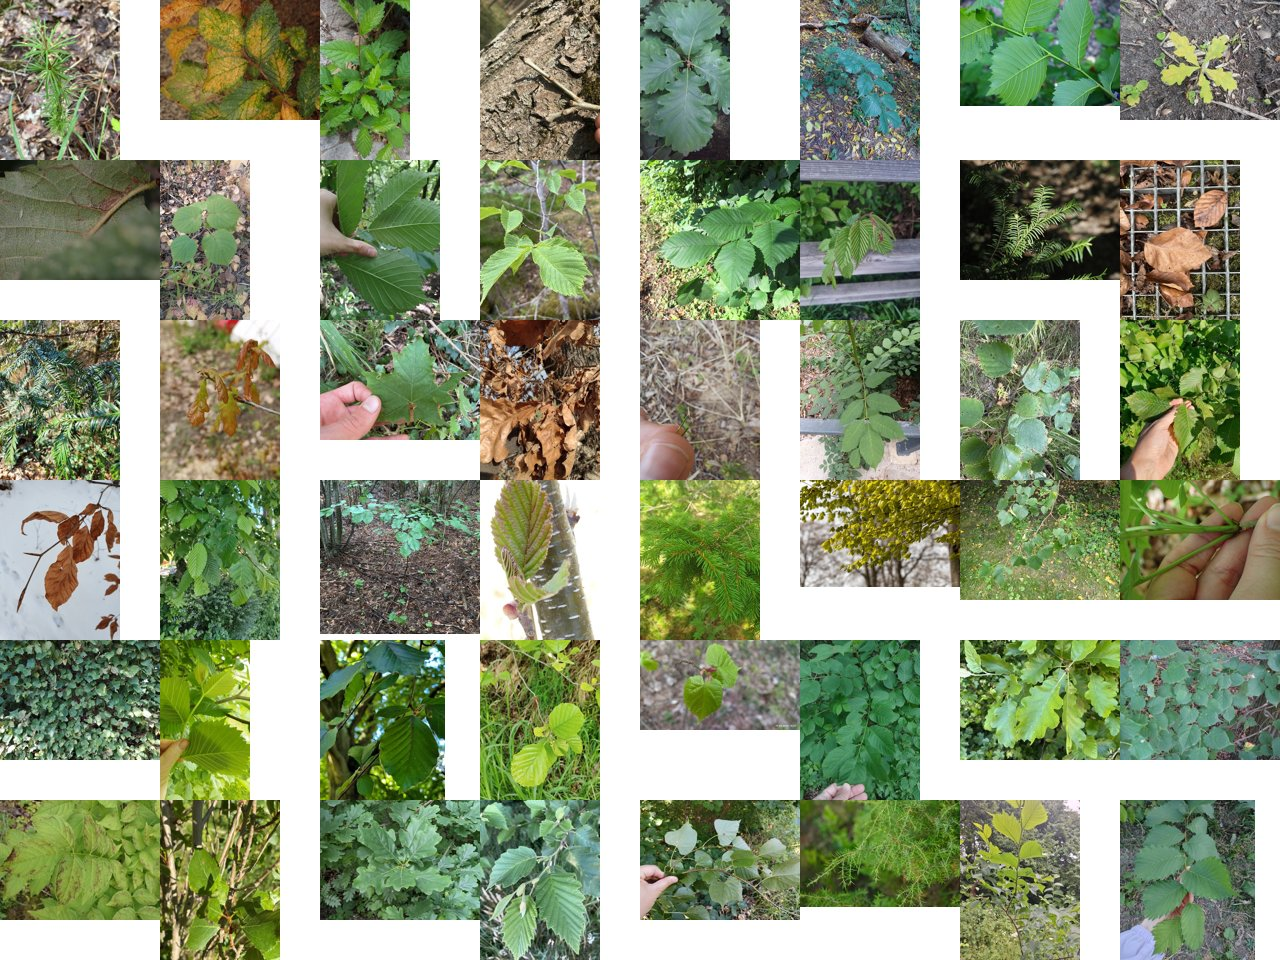

bark


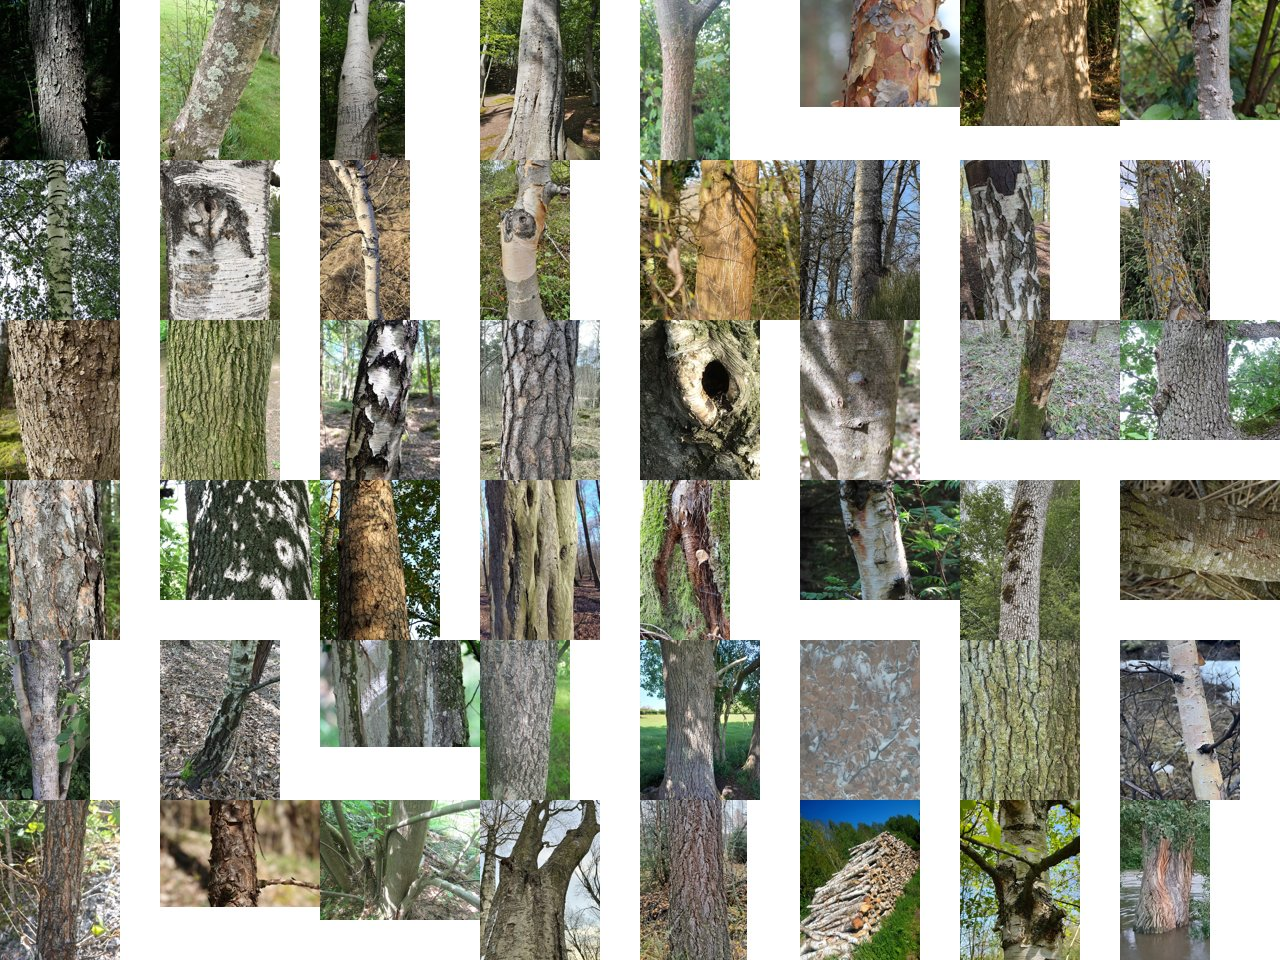

whole_tree


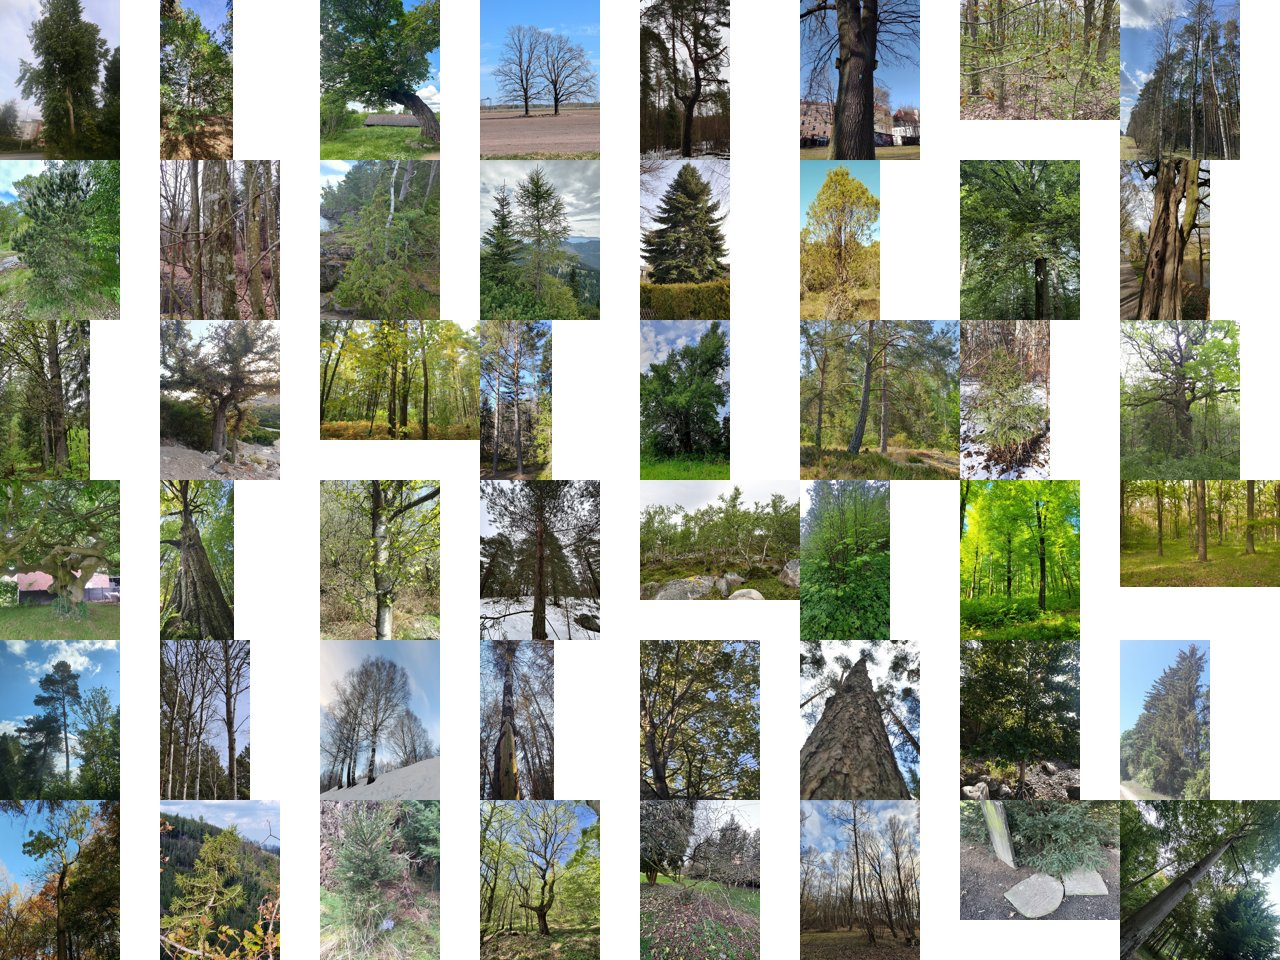

fruit


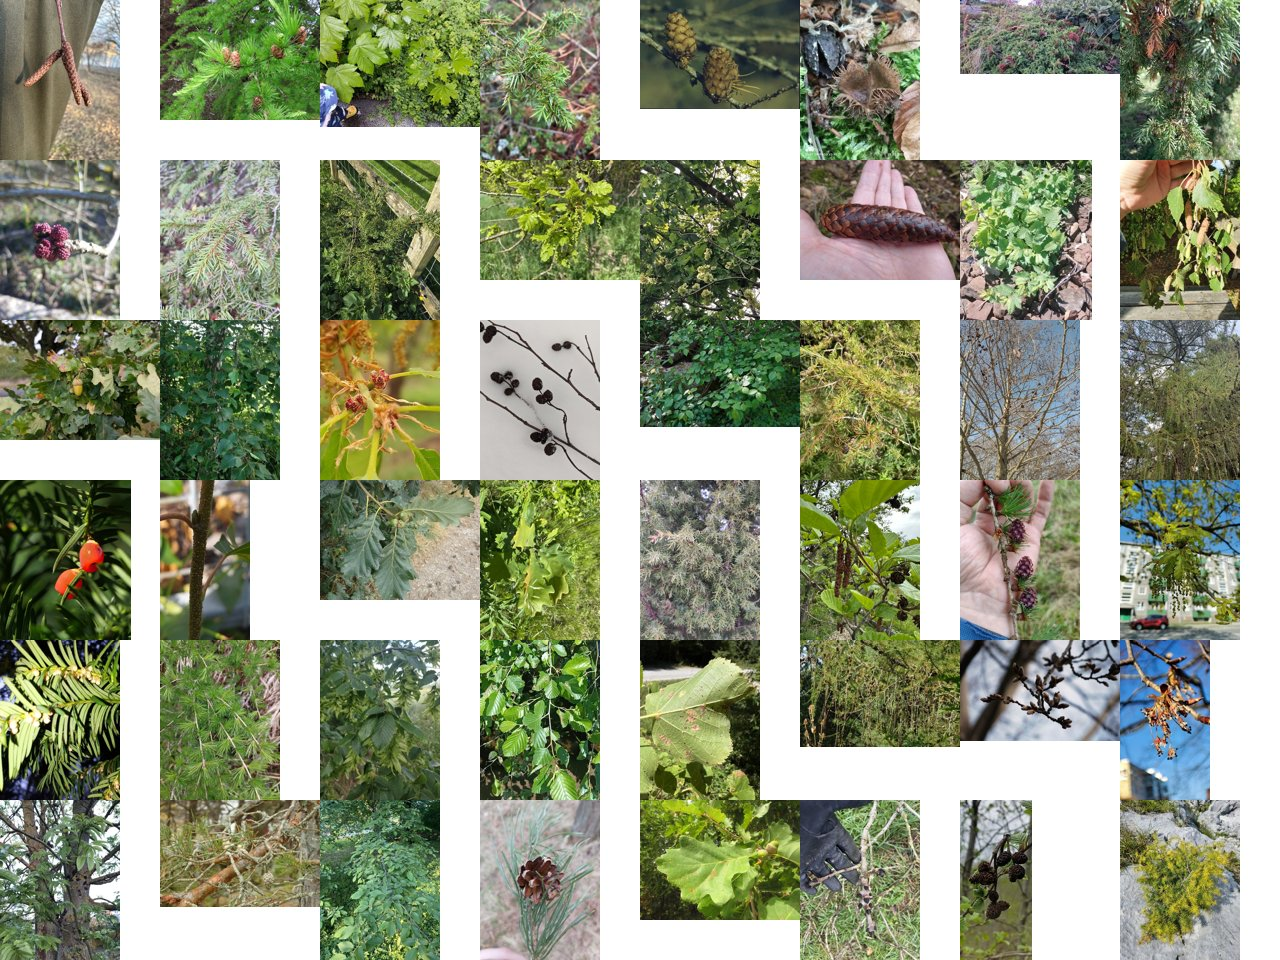

unlabeled


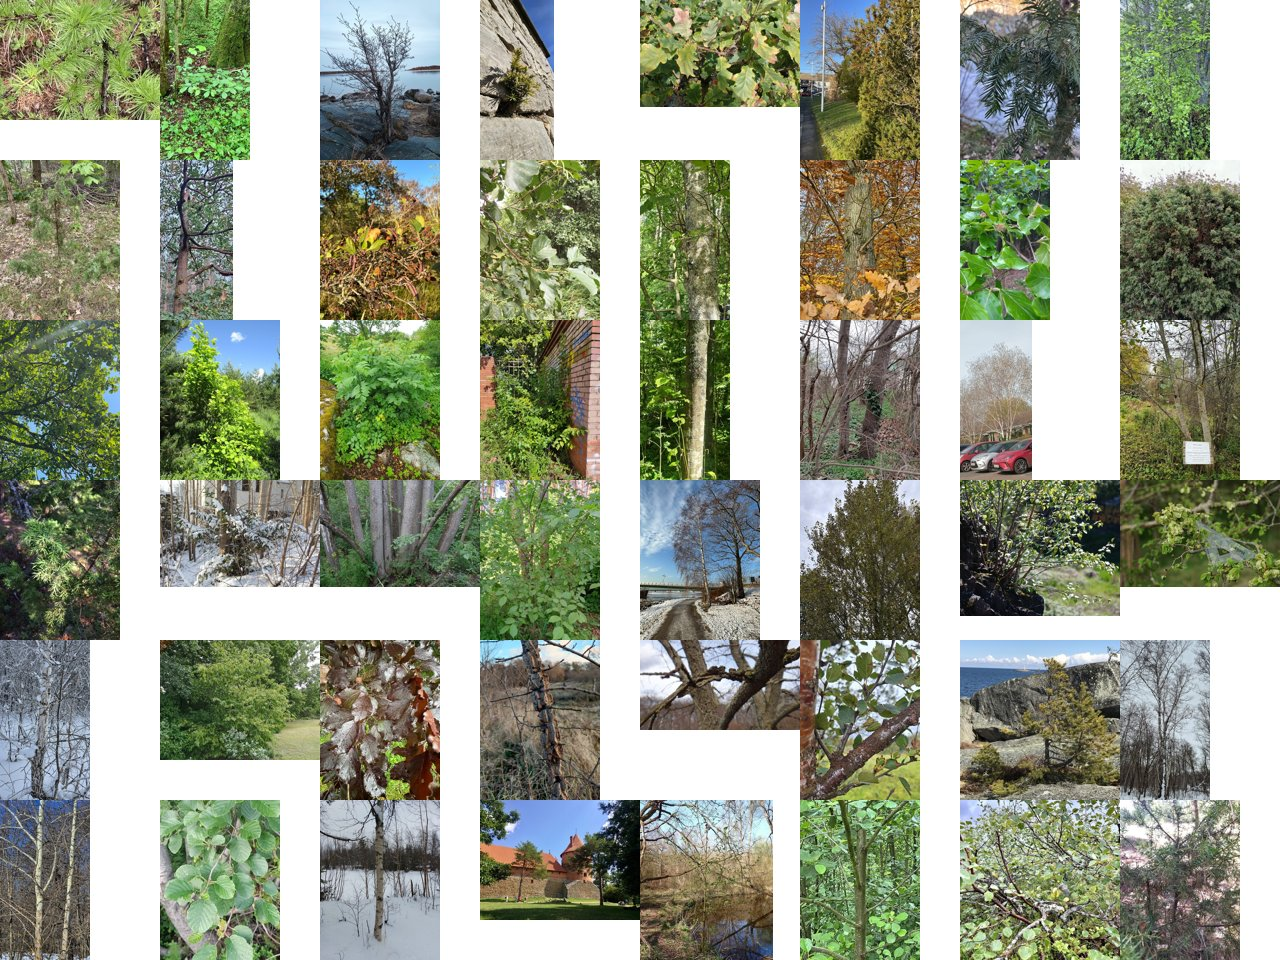

In [8]:
!python gbif_download.py review --out {DATA_ROOT}

from IPython.display import Image, display
for o in ['leaf', 'bark', 'whole_tree', 'fruit', 'unlabeled']:
    f = DATA_ROOT / 'review' / f'{o}.jpg'
    if f.exists():
        print(o); display(Image(filename=str(f)))

**Before continuing, check the table printed by step 6.** If bark or fruit counts are very low for many species, the model will be weak on those organs. You can still train, and the results will show how weak.

---
# Part B: train the model
Everything below needs the manifest and labelled images from Part A.

## 1. Locked species list (28)

In [9]:
SPECIES = {
 'Picea abies': 'Paprastoji eglė',
 'Pinus sylvestris': 'Paprastoji pušis',
 'Juniperus communis': 'Paprastasis kadagys',
 'Taxus baccata': 'Europinis kukmedis',
 'Larix decidua': 'Europinis maumedis',
 'Alnus glutinosa': 'Juodalksnis',
 'Alnus incana': 'Baltalksnis',
 'Betula pendula': 'Karpotasis beržas',
 'Betula pubescens': 'Plaukuotasis beržas',
 'Populus tremula': 'Drebulė',
 'Populus nigra': 'Juodoji tuopa',
 'Quercus robur': 'Paprastasis ąžuolas',
 'Quercus petraea': 'Bekotis ąžuolas',
 'Carpinus betulus': 'Paprastasis skroblas',
 'Tilia cordata': 'Mažalapė liepa',
 'Acer platanoides': 'Paprastasis klevas',
 'Fraxinus excelsior': 'Paprastasis uosis',
 'Fagus sylvatica': 'Paprastasis bukas',
 'Ulmus glabra': 'Kalninė guoba',
 'Ulmus laevis': 'Paprastoji vinkšna',
 'Ulmus minor': 'Paprastasis skirpstas',
 'Salix alba': 'Baltasis gluosnis',
 'Salix fragilis': 'Trapusis gluosnis',
 'Salix caprea': 'Blindė',
 'Sorbus aucuparia': 'Paprastasis šermukšnis',
 'Malus sylvestris': 'Miškinė obelis',
 'Pyrus pyraster': 'Miškinė kriaušė',
 'Prunus padus': 'Paprastoji ieva',
}
ORGANS = ['leaf', 'bark', 'whole_tree', 'fruit']
CLASSES = sorted(SPECIES)                      # fixed class order
cls2idx = {c: i for i, c in enumerate(CLASSES)}
genus_of = {c: c.split()[0] for c in CLASSES}
print(len(CLASSES), 'species')

28 species


## 2. Load and validate the manifest

In [10]:
import pandas as pd
df = pd.read_csv(MANIFEST)
need = {'file', 'species', 'organ', 'observer'}
assert need <= set(df.columns), f'manifest missing columns: {need - set(df.columns)}'

bad_sp = set(df.species) - set(CLASSES)
bad_org = set(df.organ) - set(ORGANS)
if bad_sp:  print('Unknown species (dropped):', bad_sp)
if bad_org: print('Unknown organs (dropped):', bad_org)
df = df[df.species.isin(CLASSES) & df.organ.isin(ORGANS)].copy()
df['observer'] = df['observer'].fillna('unknown').astype(str)
df['path'] = df['file'].apply(lambda f: str(DATA_ROOT / f))
df['y'] = df.species.map(cls2idx)
df['y_organ'] = df.organ.map({o: i for i, o in enumerate(ORGANS)})

missing = [p for p in df.path if not Path(p).exists()]
print('missing files:', len(missing))
df = df[df.path.map(lambda p: Path(p).exists())].reset_index(drop=True)

print(len(df), 'images')
display(df.pivot_table(index='species', columns='organ', values='file', aggfunc='count', fill_value=0))

Unknown organs (dropped): {'unlabeled'}
missing files: 0
19098 images


organ,bark,fruit,leaf,whole_tree
species,,,,
Acer platanoides,19,131,761,48
Alnus glutinosa,32,362,424,98
Alnus incana,16,309,572,42
Betula pendula,82,111,319,276
Betula pubescens,43,119,642,110
Carpinus betulus,38,193,616,113
Fagus sylvatica,16,129,659,155
Fraxinus excelsior,17,269,521,86
Juniperus communis,8,437,134,234


**Check the table above.** Species with fewer than about 100 images in total, or organs with fewer than about 30 per species, will be weak. Collect more for those before trusting the results.

## 3. Feature extraction with BioCLIP

In [11]:
import torch, numpy as np, open_clip
from PIL import Image
from tqdm.auto import tqdm

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
model, _, preprocess = open_clip.create_model_and_transforms('hf-hub:imageomics/bioclip')
model = model.to(device).eval()

class DS(torch.utils.data.Dataset):
    def __init__(self, paths, flip=False): self.paths, self.flip = paths, flip
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        try:
            im = Image.open(self.paths[i]).convert('RGB')
        except Exception:
            im = Image.new('RGB', (224, 224))      # unreadable file -> blank (flagged below)
            return preprocess(im), 0
        if self.flip: im = im.transpose(Image.FLIP_LEFT_RIGHT)
        return preprocess(im), 1

@torch.no_grad()
def embed(paths, flip=False, bs=64):
    dl = torch.utils.data.DataLoader(DS(paths, flip), batch_size=bs, num_workers=2)
    feats, ok = [], []
    for x, o in tqdm(dl):
        with torch.autocast(device, enabled=(device == 'cuda')):
            f = model.encode_image(x.to(device))
        feats.append(torch.nn.functional.normalize(f.float(), dim=-1).cpu()); ok.append(o)
    return torch.cat(feats).numpy(), torch.cat(ok).numpy().astype(bool)

CACHE = OUT_DIR / 'features.npz'
if CACHE.exists():
    z = np.load(CACHE, allow_pickle=True)
    if list(z['paths']) == list(df.path):
        X, X_flip, ok = z['X'], z['X_flip'], z['ok']
        print('loaded cached features')
    else:
        CACHE.unlink()
if not CACHE.exists():
    X, ok = embed(list(df.path))
    X_flip, _ = embed(list(df.path), flip=True)     # flipped copy = cheap augmentation for training
    np.savez(CACHE, X=X, X_flip=X_flip, ok=ok, paths=np.array(df.path))

print('unreadable images:', (~ok).sum())
df, X, X_flip = df[ok].reset_index(drop=True), X[ok], X_flip[ok]

device: cuda


open_clip_config.json:   0%|          | 0.00/469 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

  0%|          | 0/299 [00:00<?, ?it/s]

  0%|          | 0/299 [00:00<?, ?it/s]

unreadable images: 0


## 4. Split by observer
Train/val/test are split by **observer**, so the same person's near-duplicate photos never land in both train and test. This gives a more honest accuracy than a random split.

In [12]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
trainval_idx, test_idx = next(gss.split(X, df.y, groups=df.observer))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=SEED)
tr_rel, va_rel = next(gss2.split(X[trainval_idx], df.y.iloc[trainval_idx], groups=df.observer.iloc[trainval_idx]))
train_idx, val_idx = trainval_idx[tr_rel], trainval_idx[va_rel]

print('train/val/test:', len(train_idx), len(val_idx), len(test_idx))
for name, idx in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
    n = df.y.iloc[idx].nunique()
    print(f'{name}: {n}/{len(CLASSES)} species present')

train/val/test: 13244 2646 3208
train: 21/28 species present
val: 21/28 species present
test: 21/28 species present


If a species is missing from val or test, it has too few distinct observers. Add more images from more observers for it.

## 5. Train the classifiers

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

y = df.y.values
Xtr = np.concatenate([X[train_idx], X_flip[train_idx]])
ytr = np.concatenate([y[train_idx], y[train_idx]])

best = None
for C in [1, 3, 10, 30, 100]:
    clf = LogisticRegression(C=C, max_iter=2000, class_weight='balanced')
    clf.fit(Xtr, ytr)
    acc = accuracy_score(y[val_idx], clf.predict(X[val_idx]))
    print(f'C={C:<4} val acc={acc:.3f}')
    if best is None or acc > best[0]: best = (acc, C, clf)
val_acc, bestC, species_clf = best
print('best C:', bestC)

# organ classifier (used by the app to say "this looks like a bark photo")
yo = df.y_organ.values
organ_clf = LogisticRegression(C=10, max_iter=2000, class_weight='balanced')
organ_clf.fit(np.concatenate([X[train_idx], X_flip[train_idx]]), np.concatenate([yo[train_idx]] * 2))
print('organ acc (test):', accuracy_score(yo[test_idx], organ_clf.predict(X[test_idx])))

C=1    val acc=0.808
C=3    val acc=0.804
C=10   val acc=0.799
C=30   val acc=0.783
C=100  val acc=0.770
best C: 1
organ acc (test): 0.8843516209476309


## 6. Evaluate on the held-out test set

TEST top-1: 0.828   top-3: 0.950

Accuracy per organ:
  leaf        n=1875  top-1=0.876
  bark        n=68    top-1=0.485
  whole_tree  n=506   top-1=0.704
  fruit       n=759   top-1=0.823

Per-species:
                    precision    recall  f1-score   support

  Acer platanoides       0.94      0.98      0.96       121
   Alnus glutinosa       0.61      0.85      0.71       127
      Alnus incana       0.77      0.62      0.69       155
    Betula pendula       0.78      0.77      0.78       169
  Betula pubescens       0.76      0.74      0.75       148
  Carpinus betulus       0.84      0.89      0.86       172
   Fagus sylvatica       0.85      0.90      0.88       148
Fraxinus excelsior       0.82      0.93      0.88       151
Juniperus communis       0.96      0.93      0.95       135
     Larix decidua       0.90      0.87      0.89       148
  Malus sylvestris       0.00      0.00      0.00         0
       Picea abies       0.84      0.95      0.89       165
  Pinus sylvest

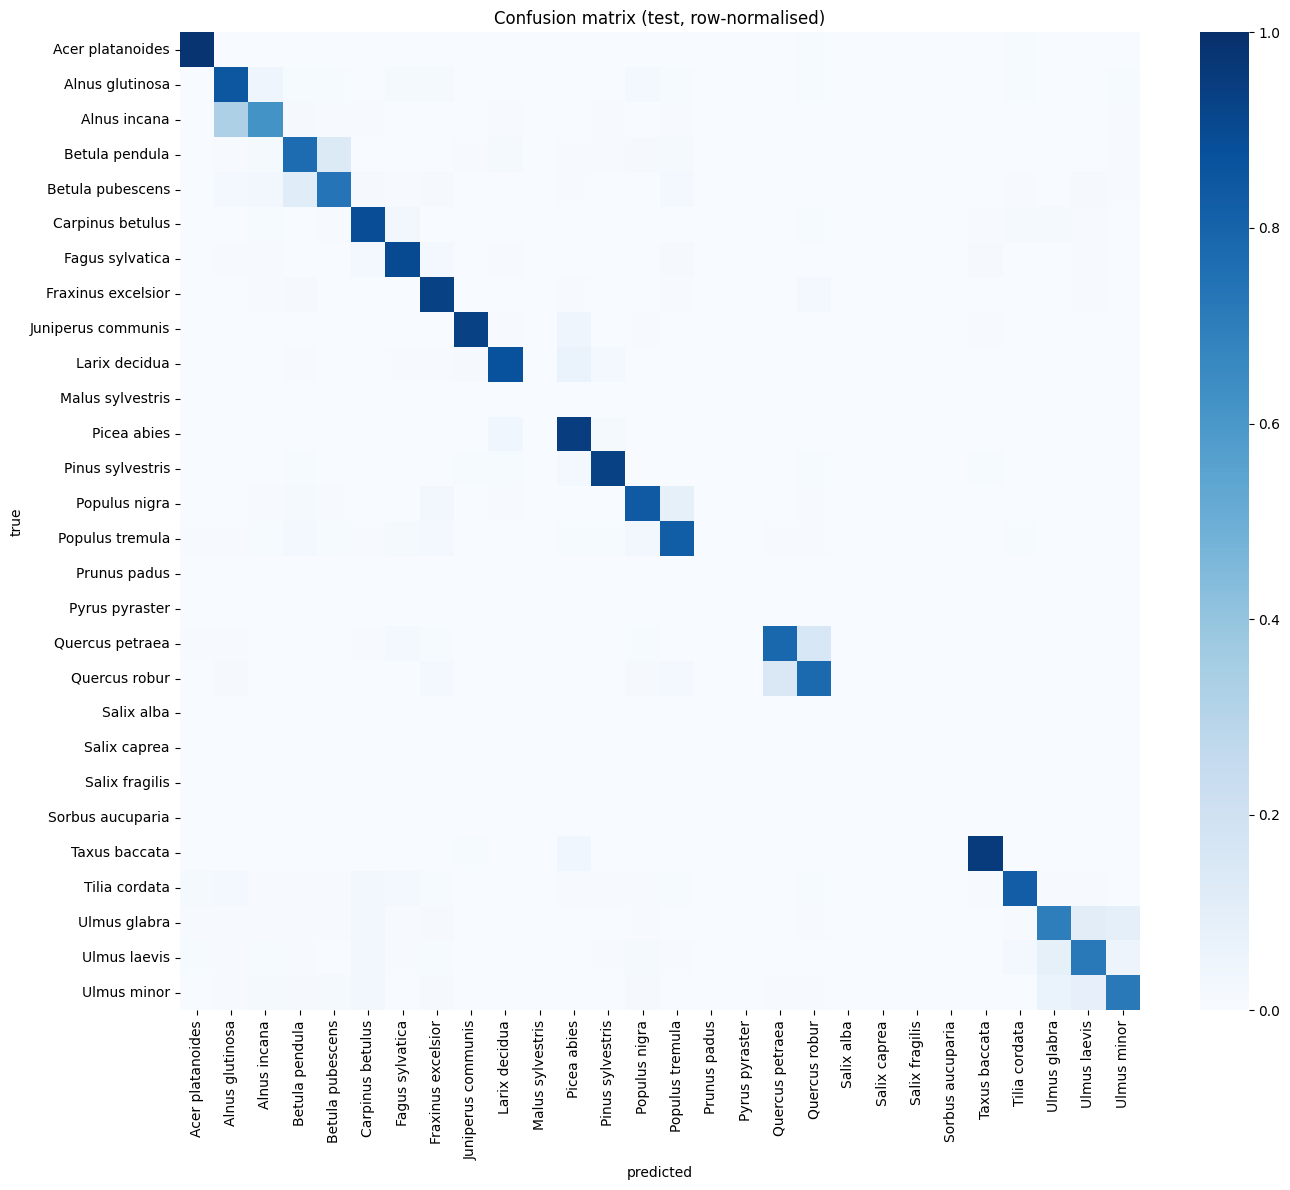


Most confused pairs (true -> predicted):
  0.33  Alnus incana -> Alnus glutinosa
  0.16  Quercus petraea -> Quercus robur
  0.15  Quercus robur -> Quercus petraea
  0.14  Betula pendula -> Betula pubescens
  0.11  Betula pubescens -> Betula pendula
  0.11  Ulmus glabra -> Ulmus laevis


In [14]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

P = species_clf.predict_proba(X[test_idx])
classes_in_model = species_clf.classes_            # classes seen in training
full = np.zeros((len(test_idx), len(CLASSES))); full[:, classes_in_model] = P
pred = full.argmax(1); yt = y[test_idx]

top1 = (pred == yt).mean()
top3 = np.mean([yt[i] in np.argsort(-full[i])[:3] for i in range(len(yt))])
print(f'TEST top-1: {top1:.3f}   top-3: {top3:.3f}')

print('\nAccuracy per organ:')
for o in ORGANS:
    m = (df.organ.iloc[test_idx].values == o)
    if m.sum(): print(f'  {o:<11} n={m.sum():<5} top-1={np.mean(pred[m]==yt[m]):.3f}')

print('\nPer-species:')
print(classification_report(yt, pred, labels=range(len(CLASSES)), target_names=CLASSES, zero_division=0))

cm = confusion_matrix(yt, pred, labels=range(len(CLASSES)), normalize='true')
plt.figure(figsize=(14, 12))
sns.heatmap(cm, xticklabels=CLASSES, yticklabels=CLASSES, cmap='Blues', vmin=0, vmax=1)
plt.xlabel('predicted'); plt.ylabel('true'); plt.title('Confusion matrix (test, row-normalised)')
plt.tight_layout(); plt.savefig(OUT_DIR / 'confusion_matrix.png', dpi=120); plt.show()

# most confused pairs
pairs = [(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j and cm[i, j] > 0.1]
print('\nMost confused pairs (true -> predicted):')
for v, a, b in sorted(pairs, reverse=True)[:15]: print(f'  {v:.2f}  {a} -> {b}')

## 7. Confidence threshold and genus fallback

When the model is unsure about the species, the app should say so. The rule:
1. If top species probability ≥ threshold, report the species.
2. Else, if the summed probability of the top genus ≥ threshold, report the genus (e.g. "Ulmus sp.").
3. Else, report "not sure", with the top 3 candidates.

The threshold is chosen on the validation set so accepted predictions are right at least 90% of the time.

In [15]:
from collections import defaultdict
genera = sorted(set(genus_of.values()))
G = np.zeros((len(CLASSES), len(genera)))
for i, c in enumerate(CLASSES): G[i, genera.index(genus_of[c])] = 1

def full_proba(Xs):
    P = species_clf.predict_proba(Xs)
    F = np.zeros((len(Xs), len(CLASSES))); F[:, species_clf.classes_] = P
    return F

def decide(F, thr):
    out = []
    for p in F:
        i = int(p.argmax())
        if p[i] >= thr: out.append(('species', i))
        else:
            gp = p @ G; g = int(gp.argmax())
            out.append(('genus', g) if gp[g] >= thr else ('unsure', None))
    return out

Fv, yv = full_proba(X[val_idx]), y[val_idx]
TARGET = 0.90
chosen = None
for thr in np.arange(0.30, 0.96, 0.05):
    d = decide(Fv, thr)
    sp = [(k, v) for k, v in zip(d, yv) if k[0] == 'species']
    acc_sp = np.mean([k[1] == v for k, v in sp]) if sp else 0
    cov_sp = len(sp) / len(yv)
    print(f'thr={thr:.2f}  species-level coverage={cov_sp:.2f}  accuracy on those={acc_sp:.3f}')
    if chosen is None and acc_sp >= TARGET and cov_sp > 0.2: chosen = float(round(thr, 2))
THRESHOLD = chosen if chosen is not None else 0.7
print('\nChosen threshold:', THRESHOLD)

# final test-set behaviour with that threshold
Ft = full_proba(X[test_idx]); d = decide(Ft, THRESHOLD)
kinds = [k for k, _ in d]
print({k: kinds.count(k) / len(kinds) for k in ['species', 'genus', 'unsure']})
sp_ok = [v == yt[i] for i, (k, v) in enumerate(d) if k == 'species']
print('species-level answers correct:', np.mean(sp_ok) if sp_ok else 'n/a')

thr=0.30  species-level coverage=0.93  accuracy on those=0.851
thr=0.35  species-level coverage=0.90  accuracy on those=0.861
thr=0.40  species-level coverage=0.86  accuracy on those=0.878
thr=0.45  species-level coverage=0.81  accuracy on those=0.896
thr=0.50  species-level coverage=0.77  accuracy on those=0.913
thr=0.55  species-level coverage=0.72  accuracy on those=0.926
thr=0.60  species-level coverage=0.68  accuracy on those=0.937
thr=0.65  species-level coverage=0.63  accuracy on those=0.943
thr=0.70  species-level coverage=0.58  accuracy on those=0.953
thr=0.75  species-level coverage=0.53  accuracy on those=0.965
thr=0.80  species-level coverage=0.47  accuracy on those=0.974
thr=0.85  species-level coverage=0.41  accuracy on those=0.987
thr=0.90  species-level coverage=0.32  accuracy on those=0.991
thr=0.95  species-level coverage=0.22  accuracy on those=0.997

Chosen threshold: 0.5
{'species': 0.8045511221945137, 'genus': 0.07418952618453865, 'unsure': 0.12125935162094763}
sp

## 8. Save the model for the web app

In [16]:
import joblib, json
joblib.dump(species_clf, OUT_DIR / 'species_clf.joblib')
joblib.dump(organ_clf,   OUT_DIR / 'organ_clf.joblib')
json.dump({
    'classes': CLASSES,
    'lithuanian': SPECIES,
    'organs': ORGANS,
    'genus_of': genus_of,
    'threshold': THRESHOLD,
    'backbone': 'hf-hub:imageomics/bioclip',
    'test_top1': float(top1), 'test_top3': float(top3),
}, open(OUT_DIR / 'config.json', 'w'), ensure_ascii=False, indent=2)
print('saved to', OUT_DIR)

saved to /content/drive/MyDrive/lt_trees/model_out


## 9. Optional: improve beyond the baseline

If test accuracy is not good enough after you have more data:
1. **Collect more images** for the weakest species and organs (see the confusion pairs above). This usually helps most.
2. **Fine-tune** the last few blocks of BioCLIP with augmentation (random crop, colour jitter, rotation), using a low learning rate (around 1e-5). Expect a few extra points of accuracy, but it takes longer and needs more care about overfitting.
3. **Train one head per organ** if one organ (usually bark) drags the overall result down. The organ classifier from step 5 can route images.
4. **Merge unresolvable pairs** into genus-level classes (e.g. the three elms) if the confusion stays high.

Next: build the Gradio app on Hugging Face Spaces using `species_clf.joblib`, `organ_clf.joblib` and `config.json`.